# Yelp Restaurant Ratings: Prediction & Exploration

Explore how restaurant attributes and review counts relate to Yelp ratings for Las Vegas restaurants. This project predicts star ratings, identifies restaurants rated **4 stars or above**, and compares predictive performance with interpretability.

The analysis uses **6,272 training restaurants** and **2,688 test restaurants**, with linear/logistic regression, decision trees, and a random forest. An interactive Dash dashboard supports group comparisons and model-based what-if exploration.

**Key result:** the random forest achieved **68.0% test accuracy**, compared with **55.1%** for the majority-class baseline. These observational patterns describe associations, not causal effects.

Run the notebook in order with `yelp_train.csv` and `yelp_test.csv` in the same folder. Install dependencies with:

```bash
pip install numpy pandas matplotlib scikit-learn plotly dash jupyter
```

The final code cell launches the dashboard locally; its tree image is generated automatically. Model tuning, especially the random forest search, may take several minutes.


## 1. Data Preparation

### Missing Restaurant Attributes

**Why it is reasonable.** On Yelp, missing attributes are unlikely to be random: they often reflect less active listings. In the training data, restaurants with more missing attributes have fewer reviews , and missing values are associated with lower ratings (e.g., 3.35 stars when `WheelechairAccessible` is missing vs. 3.96 when recorded). A separate (Missing) category lets the models use this information and keeps all observations, even for attributes that are 70–88% missing.

**Limitation.** (Missing) mixes restaurants whose true values differ, so the model learns the effect of not reporting an attribute rather than the effect of the attribute itself, which makes those results hard to interpret.

### Load Data and Encode Features

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 242  # random seed used throughout

# Data files should be in the same folder as this notebook
DATA_DIR = Path(".")
if not (DATA_DIR / "yelp_train.csv").exists():
    try:
        DATA_DIR = Path(__vsc_ipynb_file__).parent   # VS Code: folder of this notebook
    except NameError:
        pass

train = pd.read_csv(DATA_DIR / "yelp_train.csv", dtype=str)
test  = pd.read_csv(DATA_DIR / "yelp_test.csv",  dtype=str)

cat_cols = [c for c in train.columns if c not in ("stars", "review_count")]
for df in (train, test):
    df["stars"] = df["stars"].astype(float)
    df["review_count"] = df["review_count"].astype(float)
    for c in cat_cols:
        df[c] = df[c].str.strip("'")             # 'none' -> none

# One-hot encoding with an indicator for every category, incl. (Missing).
# Encode train and test together so both have the same columns in the same order.
X_all = pd.get_dummies(pd.concat([train, test], keys=["train", "test"]).drop(columns="stars"),
                       columns=cat_cols, dtype=int)

# CART / random forest: all 36 columns
X_tree_train, X_tree_test = X_all.loc["train"], X_all.loc["test"]

# Linear / logistic regression: drop the (Missing) indicators so (Missing) is the reference category
missing_cols = [c for c in X_all.columns if c.endswith("_(Missing)")]
X_lin_train = X_tree_train.drop(columns=missing_cols)
X_lin_test  = X_tree_test.drop(columns=missing_cols)

y_train, y_test = train["stars"].values, test["stars"].values

print("CART/RF inputs:", X_tree_train.shape[1], "columns")
print("Linear inputs :", X_lin_train.shape[1], "columns + intercept")
print("Train:", len(y_train), " Test:", len(y_test))

CART/RF inputs: 36 columns
Linear inputs : 25 columns + intercept
Train: 6272  Test: 2688


## 2. Predicting Star Ratings

### Linear Regression Baseline

We fit a linear regression with an intercept using all 12 predictors. `review_count` is numerical, and each categorical predictor is encoded with indicator variables, with (Missing) as the reference category (25 input columns plus intercept).

**Training-set $R^2$ = 0.1684.**

In [2]:
# Linear regression with intercept, all 12 predictors, (Missing) as reference
lin_reg = LinearRegression().fit(X_lin_train, y_train)
print(f"Training R^2: {lin_reg.score(X_lin_train, y_train):.4f}")

Training R^2: 0.1684


### Regression Tree: Cross-Validated Pruning

**Cross-validation.** We used 10-fold cross-validation on the training set only (folds shuffled with `random_state = 242`), with `min_samples_leaf = 5` fixed throughout. For each candidate `ccp_alpha` in {0, 0.0001, …, 0.005}, we trained a tree on 9 folds, computed $R^2$ on the held-out fold, repeated this for all 10 folds, and averaged the 10 values.

**Selection.** We selected the `ccp_alpha` with the highest average cross-validated $R^2$ and refit the tree with this value on the full training set. Smaller values give larger trees that overfit, and larger values prune too much, so CV $R^2$ falls on both sides of the selected value.

**Selected `ccp_alpha` = 0.0008** (44 leaves). **Cross-validation estimate of $R^2$ = 0.1728.**

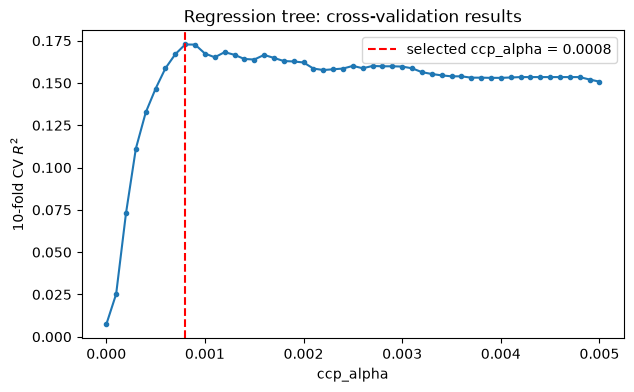

Selected ccp_alpha: 0.0008
CV estimate of R^2: 0.1728
Number of leaves  : 44


In [3]:
# Regression tree: select ccp_alpha by 10-fold cross-validation
ccp_grid = np.round(np.arange(0, 0.0051, 0.0001), 4)
cv10 = KFold(n_splits=10, shuffle=True, random_state=SEED)

cart_reg_cv = GridSearchCV(
    DecisionTreeRegressor(min_samples_leaf=5, random_state=SEED),
    param_grid={"ccp_alpha": ccp_grid},
    cv=cv10, scoring="r2"
).fit(X_tree_train, y_train)

cv_r2 = cart_reg_cv.cv_results_["mean_test_score"]
best_alpha = cart_reg_cv.best_params_["ccp_alpha"]
cart_reg = cart_reg_cv.best_estimator_          # refit on the full training set

plt.figure(figsize=(7, 4))
plt.plot(ccp_grid, cv_r2, marker="o", ms=3)
plt.axvline(best_alpha, color="red", ls="--", label=f"selected ccp_alpha = {best_alpha}")
plt.xlabel("ccp_alpha"); plt.ylabel("10-fold CV $R^2$")
plt.title("Regression tree: cross-validation results")
plt.legend(); plt.show()

print(f"Selected ccp_alpha: {best_alpha}")
print(f"CV estimate of R^2: {cart_reg_cv.best_score_:.4f}")
print(f"Number of leaves  : {cart_reg.get_n_leaves()}")

### Held-Out Regression Performance

| Model | $OSR^2$ | RMSE | MAE |
|---|---|---|---|
| Linear regression | 0.1628 | 0.7823 | 0.6301 |
| Regression tree (CART) | 0.1669 | 0.7804 | 0.6154 |

$OSR^2$ uses the training-set mean as the baseline prediction.

**Judgment.** The two models perform almost the same, with CART slightly better on all three metrics, most noticeably on MAE (0.615 vs. 0.630). Both test $OSR^2$ values are close to the training/CV $R^2$ (about 0.17), so neither model appears to overfit. However, both explain only about 16–17% of the variation in ratings, and the typical error is still large: RMSE of about 0.78 stars, compared with a standard deviation of about 0.86 stars in the test ratings. The available attributes miss key drivers of ratings such as food quality, service, and price, so neither model predicts the exact star rating well.

In [4]:
# Test-set performance
def osr2(y_true, y_pred, y_train_mean):
    """Out-of-sample R^2; baseline predicts the training-set mean."""
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_train_mean) ** 2)

preds = {"Linear regression": lin_reg.predict(X_lin_test),
         "Regression tree (CART)": cart_reg.predict(X_tree_test)}

results_b = pd.DataFrame({
    name: {"OSR^2": osr2(y_test, p, y_train.mean()),
           "RMSE": np.sqrt(mean_squared_error(y_test, p)),
           "MAE": mean_absolute_error(y_test, p)}
    for name, p in preds.items()}).T.round(4)

results_b

,OSR^2,RMSE,MAE
Linear regression,0.1628,0.7823,0.6301
Regression tree (CART),0.1669,0.7804,0.6154


## 3. Identifying Restaurants Rated 4+

### Error Trade-offs
A false positive occurs when the model predicts that a restaurant has a rating of at least 4 stars, but its actual rating is below 4. A false negative occurs when the model predicts a rating below 4, but the actual rating is at least 4. Weighting these errors equally is a reasonable starting point because no specific costs are given for either type of error. However, for restaurant recommendations, false positives may be more costly because they could lead to disappointing customer experiences.

### Thresholded Regression Baselines

We define fourOrAbove = 1 if stars ≥ 4 and 0 otherwise, in both the training and test sets. To use the regression models from the star-rating analysis as classifiers, we predict fourOrAbove = 1 when a model's predicted star rating is at least 4, and 0 otherwise.

In the test set, 44.9% of restaurants have fourOrAbove = 1, but the thresholded linear regression and regression tree predict this for only 318 and 283 of the 2,688 restaurants (about 12% and 11%). Regression predictions are pulled toward the average rating (about 3.5 stars), so they rarely exceed 4. Thresholding them at 4 therefore labels most restaurants as below 4. Test-set performance of these classifiers is reported in the classifier comparison.

In [5]:
# Define fourOrAbove and threshold the regression predictions at 4
y4_train = (y_train >= 4).astype(int)
y4_test  = (y_test  >= 4).astype(int)

pred_lin_thr  = (lin_reg.predict(X_lin_test)   >= 4).astype(int)
pred_cart_thr = (cart_reg.predict(X_tree_test) >= 4).astype(int)

print(f"Share with fourOrAbove = 1: train {y4_train.mean():.3f}, test {y4_test.mean():.3f}")
print(f"Linear regression (thresholded): {pred_lin_thr.sum()} of {len(y4_test)} test restaurants predicted 4+")
print(f"Regression tree (thresholded)  : {pred_cart_thr.sum()} of {len(y4_test)} test restaurants predicted 4+")

Share with fourOrAbove = 1: train 0.438, test 0.449
Linear regression (thresholded): 318 of 2688 test restaurants predicted 4+
Regression tree (thresholded)  : 283 of 2688 test restaurants predicted 4+


### Logistic Regression

We fit a logistic regression of fourOrAbove with an intercept using all 12 predictors, with (Missing) as the reference category for each categorical predictor (the same 25 input columns as the linear regression). The model is estimated by maximum likelihood without regularization (`C=np.inf`), and a restaurant is classified as fourOrAbove = 1 when its predicted probability is at least 0.5.

**Training-set accuracy = 0.6773.**

In [6]:
# Logistic regression by maximum likelihood (no regularization), (Missing) as reference
log_reg = LogisticRegression(C=np.inf, solver="newton-cholesky", max_iter=1000).fit(X_lin_train, y4_train)
print(f"Training accuracy: {log_reg.score(X_lin_train, y4_train):.4f}")

Training accuracy: 0.6773


### Classification Tree: Tuning and Interpretation

**Cross-validation.** We used stratified 10-fold cross-validation on the training set only (folds shuffled with `random_state = 242`), so that each fold has about the same share of fourOrAbove = 1 as the full training set. The minimum leaf size was fixed at `min_samples_leaf = 5`. For each candidate `ccp_alpha` in {0, 0.0002, …, 0.01}, we trained a tree on 9 folds, computed accuracy on the held-out fold, repeated this for all 10 folds, and averaged the 10 accuracies.

**Selection.** We selected the `ccp_alpha` with the highest average cross-validated accuracy, **`ccp_alpha` = 0.0006**, and refit the tree with this value on the full training set (40 leaves, depth 9). Smaller values give larger trees that overfit, and larger values prune away useful splits, so CV accuracy falls on both sides.

**Cross-validation estimate of accuracy = 0.6653.**

**Reading the tree.** Each node shows the share of training restaurants it contains and the proportions [below 4, 4 or above]. The first split is whether `WheelechairAccessible` is reported. Restaurants that report it are mostly predicted to be 4+ (69.5% are 4+), especially when `ByAppointmentOnly` is also reported (82.9%). Restaurants that do not report it are mostly predicted below 4. Within that group, the tree splits further on `review_count`, `RestaurantsReservations`, and other attributes, and restaurants with more than 947 reviews are predicted to be 4+.

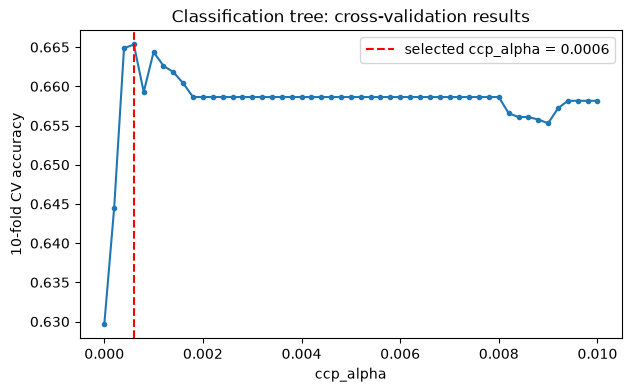

Selected ccp_alpha     : 0.0006
CV estimate of accuracy: 0.6653
Number of leaves       : 40,  depth: 9


In [7]:
# Classification tree: select ccp_alpha by stratified 10-fold cross-validation
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold

ccp_grid_cls = np.round(np.arange(0, 0.0101, 0.0002), 4)
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

cart_cls_cv = GridSearchCV(
    DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED),
    param_grid={"ccp_alpha": ccp_grid_cls},
    cv=skf10, scoring="accuracy"
).fit(X_tree_train, y4_train)

cv_acc = cart_cls_cv.cv_results_["mean_test_score"]
best_alpha_cls = cart_cls_cv.best_params_["ccp_alpha"]
cart_cls = cart_cls_cv.best_estimator_          # refit on the full training set

plt.figure(figsize=(7, 4))
plt.plot(ccp_grid_cls, cv_acc, marker="o", ms=3)
plt.axvline(best_alpha_cls, color="red", ls="--", label=f"selected ccp_alpha = {best_alpha_cls}")
plt.xlabel("ccp_alpha"); plt.ylabel("10-fold CV accuracy")
plt.title("Classification tree: cross-validation results")
plt.legend(); plt.show()

print(f"Selected ccp_alpha     : {best_alpha_cls}")
print(f"CV estimate of accuracy: {cart_cls_cv.best_score_:.4f}")
print(f"Number of leaves       : {cart_cls.get_n_leaves()},  depth: {cart_cls.get_depth()}")

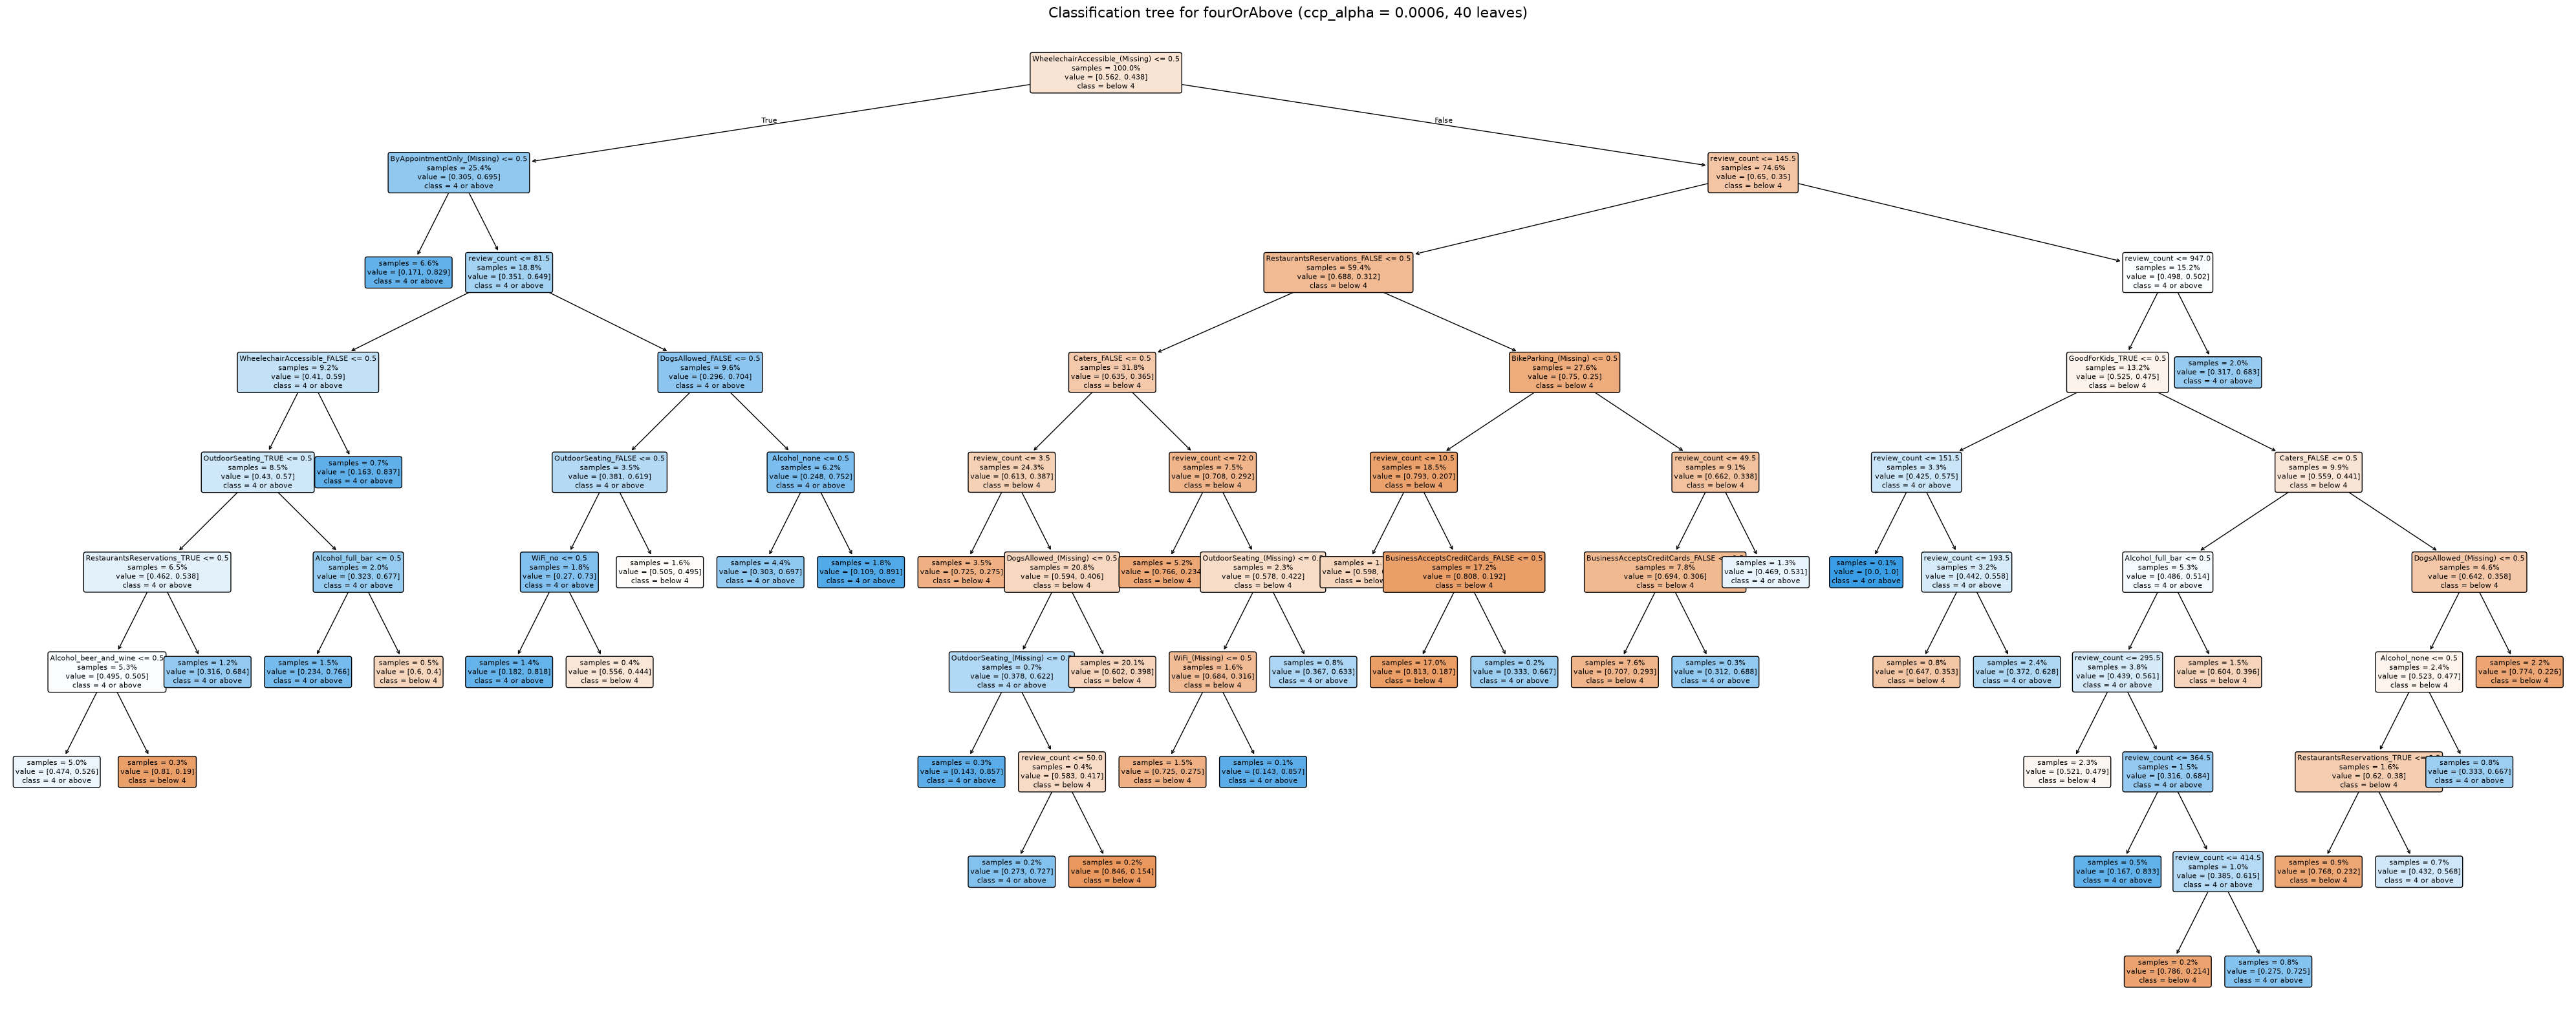

In [8]:
# Diagram of the fitted classification tree
fig, ax = plt.subplots(figsize=(40, 16))
plot_tree(cart_cls, feature_names=list(X_tree_train.columns), class_names=["below 4", "4 or above"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Classification tree for fourOrAbove (ccp_alpha = {best_alpha_cls}, "
             f"{cart_cls.get_n_leaves()} leaves)", fontsize=16)
plt.tight_layout()
plt.savefig("classification_tree.png", dpi=150, bbox_inches="tight")   # high-resolution copy for zooming
plt.show()

### Random Forest: Tuning Feature Sampling

**Cross-validation.** We fit random forests with `n_estimators = 500`, `min_samples_leaf = 5`, and no pruning, using stratified 5-fold cross-validation on the training set (`random_state = 242`). For each candidate `max_features` in {1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 36}, we trained on 4 folds, computed accuracy on the held-out fold, and averaged over the 5 folds. The grid is denser for small values, where accuracy changes most.

**Selection.** We chose the value with the highest average CV accuracy and refit the forest on the full training set.

**Selected `max_features` = 6. CV estimate of accuracy = 0.6870.**

**What `max_features` controls.** It is the number of randomly chosen input columns each tree considers at each split. A smaller value makes trees split on different variables, so the trees are more diverse and averaging them reduces variance more, but each tree is weaker. A larger value lets all trees use the same strong variables, so they become similar and averaging helps less (36 is plain bagging). Here, accuracy peaks at 4–6 and declines for larger values, so a moderate value balances tree strength and diversity best.

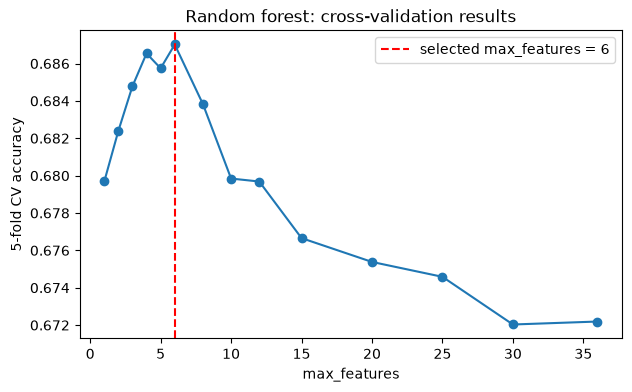

Selected max_features  : 6
CV estimate of accuracy: 0.6870


In [9]:
# Random forest: 500 trees, min_samples_leaf = 5, select max_features by stratified 5-fold CV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

mf_grid = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 36]
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rf_cv = GridSearchCV(
    RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    param_grid={"max_features": mf_grid},
    cv=skf5, scoring="accuracy"
).fit(X_tree_train, y4_train)

rf_acc = rf_cv.cv_results_["mean_test_score"]
best_mf = rf_cv.best_params_["max_features"]
rf = rf_cv.best_estimator_                       # refit on the full training set

plt.figure(figsize=(7, 4))
plt.plot(mf_grid, rf_acc, marker="o")
plt.axvline(best_mf, color="red", ls="--", label=f"selected max_features = {best_mf}")
plt.xlabel("max_features"); plt.ylabel("5-fold CV accuracy")
plt.title("Random forest: cross-validation results")
plt.legend(); plt.show()

print(f"Selected max_features  : {best_mf}")
print(f"CV estimate of accuracy: {rf_cv.best_score_:.4f}")

### Classifier Comparison and Model Selection

| Model | Accuracy | TPR | FPR |
|---|---|---|---|
| Baseline (most frequent class) | 0.5513 | 0.0000 | 0.0000 |
| Linear regression, thresholded | 0.6161 | 0.2040 | 0.0486 |
| Regression tree, thresholded | 0.6135 | 0.1866 | 0.0391 |
| Logistic regression | 0.6656 | 0.4826 | 0.1856 |
| Classification tree (CART) | 0.6522 | 0.4834 | 0.2105 |
| Random forest | 0.6801 | 0.5224 | 0.1916 |

**Are the results reasonable?** Yes. The most frequent training class is "below 4", so the baseline always predicts 0, giving TPR = FPR = 0 and accuracy equal to the share of test restaurants below 4 (55.1%). Every model beats it. The test accuracies are close to the training and CV estimates (logistic regression 0.677, classification tree 0.665, random forest 0.687), although this comparison alone cannot rule out overfitting. As the thresholded predictions show, the thresholded regression models rarely predict 4+, so they have a very low FPR but miss most 4+ restaurants (TPR around 0.2).

**Judgment and trade-offs.** The three classification models clearly outperform the thresholded regressions, because they are trained for this task directly. Random forest has the highest accuracy (0.680) and TPR (0.522), with an FPR similar to logistic regression's. Logistic regression is close behind (0.666), and the classification tree is lowest of the three (0.652) with the highest FPR. The gains are modest overall: the best model improves accuracy by about 13 percentage points over the baseline, since the attributes capture only part of what drives ratings. The trade-off is interpretability: logistic regression gives one coefficient per attribute level and the tree gives simple rules, while the random forest averages 500 trees and is hard to explain.

**Recommendation.** Since we weight false positives and false negatives equally and focus on accuracy, we recommend the **random forest**, which has the highest test accuracy and catches the most 4+ restaurants with a lower false positive rate than the classification tree, but a slightly higher rate than logistic regression. If the model must be explained to restaurant owners, logistic regression is a reasonable alternative, giving up about 1.5 percentage points of accuracy for much better interpretability.

In [10]:
# Test-set accuracy, TPR and FPR for the six models
from sklearn.metrics import confusion_matrix

def cls_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"Accuracy": (tp + tn) / len(y_true), "TPR": tp / (tp + fn), "FPR": fp / (fp + tn)}

majority = int(y4_train.mean() >= 0.5)           # most frequent training class
test_preds = {
    "Baseline (most frequent class)": np.full(len(y4_test), majority),
    "Linear regression, thresholded": pred_lin_thr,
    "Regression tree, thresholded":   pred_cart_thr,
    "Logistic regression":            log_reg.predict(X_lin_test),
    "Classification tree (CART)":     cart_cls.predict(X_tree_test),
    "Random forest":                  rf.predict(X_tree_test),
}
results_c = pd.DataFrame({name: cls_metrics(y4_test, p) for name, p in test_preds.items()}).T.round(4)
print(f"Most frequent training class: {majority}")
results_c

Most frequent training class: 0


,Accuracy,TPR,FPR
Baseline (most frequent class),0.5513,0.0000,0.0000
"Linear regression, thresholded",0.6161,0.2040,0.0486
"Regression tree, thresholded",0.6135,0.1866,0.0391
Logistic regression,0.6656,0.4826,0.1856
Classification tree (CART),0.6522,0.4834,0.2105
Random forest,0.6801,0.5224,0.1916


## 4. Interactive Ratings Explorer

**How to run.** Install Dash and Plotly (`pip install dash plotly`), run all previous cells (the dashboard uses the training data, `y4_train`, and the logistic regression `log_reg` fitted earlier), then run the dashboard cell below. The dashboard has two tabs:

1. **Compare restaurant groups**: choose an attribute (or profile completeness / review-count group) and a review-count range. It shows the number of restaurants (n), average stars, and the share rated 4+ for each group.
2. **What-if prediction**: enter a restaurant profile and choose one attribute to vary. The logistic regression fitted earlier shows the predicted probability of a 4+ rating for each level of that attribute, holding the rest of the profile fixed.

In [ ]:
# Interactive dashboard: opens as a web page (run all earlier cells first; needs `pip install dash`)
import plotly.graph_objects as go
from dash import Dash, dcc, html, dash_table, Input, Output

# Reuse the notebook's training data and the logistic regression `log_reg` fitted earlier
ddf = train.copy()
ddf["fourOrAbove"] = y4_train
levels = {c: sorted(ddf[c].unique()) for c in cat_cols}

# Grouping variables for the comparison tab
ddf["n_missing"] = (ddf[cat_cols] == "(Missing)").sum(axis=1)
ddf["Profile completeness"] = pd.cut(ddf["n_missing"], [-1, 2, 5, 8, 11],
                                     labels=["0-2 missing", "3-5 missing", "6-8 missing", "9-11 missing"])
ddf["Review count group"] = pd.cut(ddf["review_count"], [0, 10, 30, 100, 300, np.inf],
                                   labels=["3-10", "11-30", "31-100", "101-300", "300+"])
group_options = ["Profile completeness", "Review count group"] + cat_cols
RC_MAX = int(ddf["review_count"].max())
rc_marks = [3, 10, 30, 100, 300, 1000, RC_MAX]          # slider positions -> review counts


def group_summary(attr, rc_min, rc_max):
    d = ddf[(ddf["review_count"] >= rc_min) & (ddf["review_count"] <= rc_max)]
    out = d.groupby(attr, observed=True).agg(n=("stars", "size"), avg_stars=("stars", "mean"),
                                             pct_4plus=("fourOrAbove", "mean"))
    out["pct_4plus"] *= 100
    return out.round(2).reset_index(), d


def profile_to_X(profile):
    row = pd.DataFrame(0, index=[0], columns=X_lin_train.columns)
    row["review_count"] = profile["review_count"]
    for c in cat_cols:
        col = f"{c}_{profile[c]}"
        if col in row.columns:      # (Missing) is the reference level and has no column
            row[col] = 1
    return row


def what_if(profile, attr):
    probs = [log_reg.predict_proba(profile_to_X({**profile, attr: lv}))[0, 1] for lv in levels[attr]]
    return pd.Series(probs, index=levels[attr])


# ---------------- Layout ----------------
app = Dash(__name__, title="Yelp Ratings Explorer")
label = {"fontWeight": "600", "marginTop": "8px"}

tab1 = html.Div([
    html.Div([
        html.Div([html.Div("Group restaurants by", style=label),
                  dcc.Dropdown(group_options, "Profile completeness", id="attr", clearable=False)],
                 style={"width": "320px"}),
        html.Div([html.Div("Number of reviews", style=label),
                  dcc.RangeSlider(0, len(rc_marks) - 1, step=1, value=[0, len(rc_marks) - 1], id="rc",
                                  marks={i: str(v) for i, v in enumerate(rc_marks)}, allow_direct_input=False)],
                 style={"width": "480px"}),
    ], style={"display": "flex", "gap": "40px", "flexWrap": "wrap"}),
    dcc.Graph(id="group-chart"),
    dash_table.DataTable(id="group-table", style_cell={"textAlign": "center", "fontFamily": "sans-serif"},
                         style_header={"fontWeight": "bold"}),
], style={"padding": "16px"})

profile_inputs = [html.Div([html.Div(c, style=label),
                            dcc.Dropdown(levels[c], "(Missing)", id=f"p-{c}", clearable=False)])
                  for c in cat_cols]
profile_inputs.append(html.Div([html.Div("review_count", style=label),
                                dcc.Input(id="p-review_count", type="number", value=50, min=3, max=20000)]))
tab2 = html.Div([
    html.Div(profile_inputs, style={"width": "300px"}),
    html.Div([
        html.Div("Compare levels of", style=label),
        dcc.Dropdown(cat_cols, "Caters", id="vary", clearable=False, style={"width": "300px"}),
        dcc.Graph(id="whatif-chart"),
        html.Div(id="whatif-text"),
    ], style={"flex": "1", "minWidth": "350px"}),
], style={"display": "flex", "gap": "40px", "padding": "16px", "flexWrap": "wrap"})

app.layout = html.Div([
    html.H2("Yelp Las Vegas restaurants: what is associated with a 4+ star rating?"),
    html.P("Training data: 6,272 restaurants. Patterns show associations, not causal effects."),
    dcc.Tabs([dcc.Tab(label="Compare restaurant groups", children=tab1),
              dcc.Tab(label="What-if prediction (logistic regression)", children=tab2)]),
], style={"fontFamily": "sans-serif", "maxWidth": "1100px", "margin": "auto", "padding": "16px"})


# ---------------- Callbacks ----------------
@app.callback(Output("group-chart", "figure"), Output("group-table", "data"), Output("group-table", "columns"),
              Input("attr", "value"), Input("rc", "value"))
def update_groups(attr, rc):
    rc_min, rc_max = rc_marks[rc[0]], rc_marks[rc[1]]
    summ, d = group_summary(attr, rc_min, rc_max)
    overall = 100 * d["fourOrAbove"].mean() if len(d) else 0
    fig = go.Figure(go.Bar(x=summ[attr].astype(str), y=summ["pct_4plus"], marker_color="#4C78A8",
                           text=[f"{p:.1f}%<br>n={n}" for p, n in zip(summ["pct_4plus"], summ["n"])],
                           textposition="outside"))
    fig.add_hline(y=overall, line_dash="dash", line_color="gray",
                  annotation_text=f"all selected: {overall:.1f}%", annotation_position="top left")
    fig.update_layout(title=f"Share rated 4+ by {attr} ({rc_min}-{rc_max} reviews, {len(d)} restaurants)",
                      yaxis=dict(title="% rated 4+ stars", range=[0, 105]), template="plotly_white",
                      margin=dict(t=60, b=40))
    table = summ.rename(columns={attr: "Group", "n": "Restaurants (n)", "avg_stars": "Avg stars",
                                 "pct_4plus": "% rated 4+"})
    table["Group"] = table["Group"].astype(str)
    return fig, table.to_dict("records"), [{"name": c, "id": c} for c in table.columns]


@app.callback(Output("whatif-chart", "figure"), Output("whatif-text", "children"),
              [Input(f"p-{c}", "value") for c in cat_cols] + [Input("p-review_count", "value"), Input("vary", "value")])
def update_whatif(*args):
    profile = dict(zip(cat_cols, args[:len(cat_cols)]))
    profile["review_count"] = args[len(cat_cols)] or 3
    attr = args[-1]
    probs = 100 * what_if(profile, attr)
    n_level = ddf[attr].value_counts()
    fig = go.Figure(go.Bar(x=probs.index, y=probs.values, marker_color="#F58518",
                           text=[f"{p:.1f}%<br>(n={n_level[lv]})" for lv, p in probs.items()],
                           textposition="outside"))
    fig.update_layout(title=f"Predicted chance of 4+ stars when changing {attr}, all else fixed",
                      yaxis=dict(title="Predicted P(4+ stars), %", range=[0, 105]), template="plotly_white",
                      margin=dict(t=60, b=40))
    p_now = 100 * log_reg.predict_proba(profile_to_X(profile))[0, 1]
    return fig, [html.P(f"Predicted chance of 4+ stars for the profile as entered: {p_now:.1f}%"),
                 html.P("n = training restaurants with that level.", style={"color": "gray"})]

app.run(jupyter_mode="external", port=8050)   # prints a link; open http://127.0.0.1:8050 in a browser


**Example.** An owner who does not offer catering wants to know whether catering is linked to higher ratings. In Tab 1, grouping by `Caters` shows that 54.4% of restaurants that cater are rated 4+ (n = 1,967), versus 40.1% of those that do not (n = 2,186), a gap of about 14 percentage points. Part of this gap may come from other differences between these restaurants, so in Tab 2 the owner varies only `Caters` for a restaurant with 50 reviews and all other attributes unreported. The model predicts a 43.0% chance of 4+ with catering versus 33.6% without, a smaller gap of about 9 points. The user learns that catering is associated with higher ratings even after accounting for the other listed attributes, but the association is weaker than the raw comparison suggests.

[Screenshot 1: Tab 1, grouped by Caters]
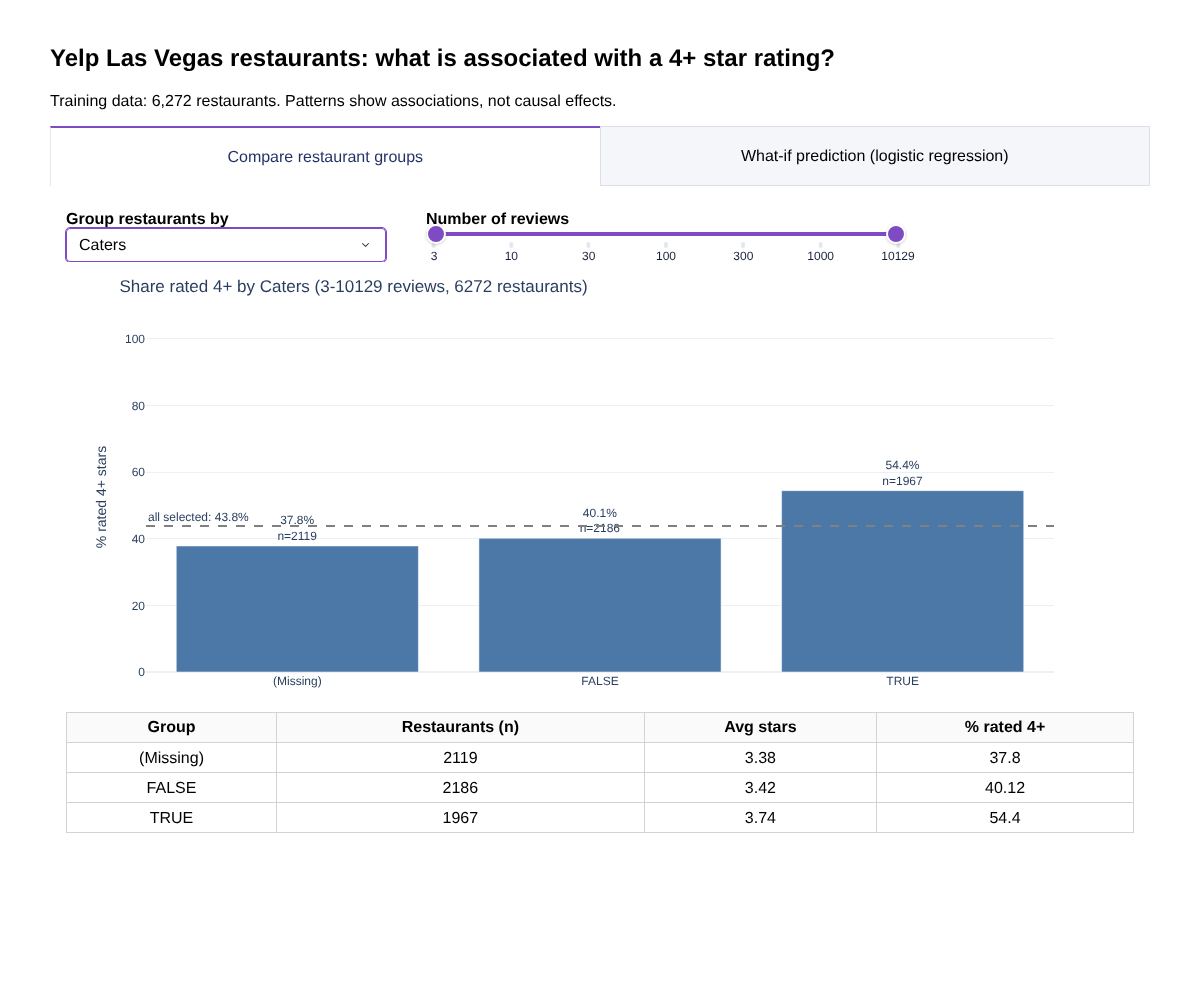
[Screenshot 2: Tab 2, comparing levels of Caters]
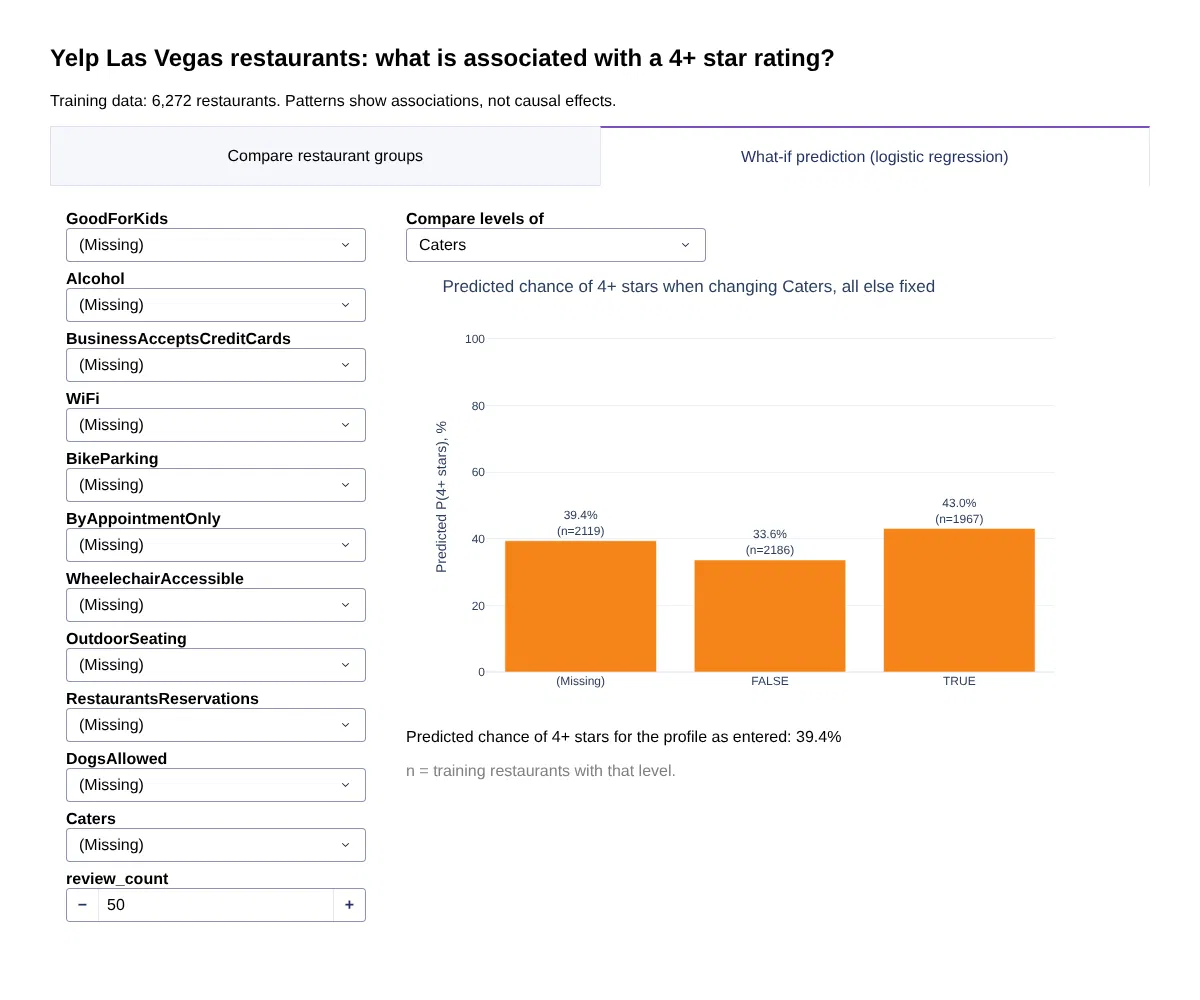

Dashboard group summaries are calculated from the training data, and what-if probabilities use the fitted logistic regression model.

**Three takeaways for restaurant owners**

1. **Restaurants with complete Yelp profiles are rated higher.** 64.0% of restaurants with at most 2 missing attributes are rated 4+ (n = 1,663), compared with 34.5–39.5% for restaurants with more missing attributes (n = 896–2,360 per group). Whether `WheelechairAccessible` is reported is also the first split in the classification tree. This is likely a sign of engaged owners rather than a cause of good ratings, but completing your profile is cheap and worth trying.
2. **Highly reviewed restaurants are more often rated 4+.** 65.1% of restaurants with more than 300 reviews are rated 4+ (n = 931), versus 35–38% for those with 100 or fewer (n = 1,253–1,589 per group). Popularity probably follows from quality rather than the reverse, so collecting more reviews will not by itself raise a rating. Owners with few reviews should know that their rating is based on little data and can change quickly.
3. **Catering and taking reservations are associated with higher ratings.** Restaurants that cater are rated 4+ more often (54.4% vs. 40.1%), as are restaurants that take reservations (54.3%, n = 1,481, vs. 37.9%, n = 2,808). These services may signal a more established, full-service restaurant. The model still predicts a higher chance of 4+ with catering after holding other listed attributes fixed (43.0% vs. 33.6% in the example), but this is an association in observational data, not evidence that adding catering would raise a rating. It is a question worth testing, for example by tracking ratings before and after a change.

## Appendix: Regression Tree Foundations

A short derivation of why a split cannot increase training residual sum of squares, and why this does not guarantee better predictions on new data.


### Impurity Before a Split

Before the split, the tree has a single terminal node containing all $n$ observations. The tree predicts the sample mean of all outcomes for every observation:

$$\hat y = \bar y = \frac{1}{n}\sum_{i=1}^{n} y_i$$

The total impurity before the split is the training RSS of this single node:

$$\text{RSS}_{\text{before}} = \sum_{i=1}^{n}\left(y_i-\bar y\right)^2$$

### Impurity After a Split

After the split, the tree has two terminal nodes. Each node predicts the sample mean of the outcomes in that node:

$$\bar y_1 = \frac{1}{N}\sum_{i=1}^{N} y_i \quad \text{(node 1)}, \qquad \bar y_2 = \frac{1}{n-N}\sum_{i=N+1}^{n} y_i \quad \text{(node 2)}$$

The total impurity after the split is the sum of the RSS in the two terminal nodes:

$$\text{RSS}_{\text{after}} = \sum_{i=1}^{N}\left(y_i-\bar y_1\right)^2 + \sum_{i=N+1}^{n}\left(y_i-\bar y_2\right)^2$$

### Why Splits Reduce Training Error

**Proof.** Write the total impurity before the split as a sum over the same two groups:

$$\text{RSS}_{\text{before}} = \sum_{i=1}^{N}(y_i-\bar y)^2 + \sum_{i=N+1}^{n}(y_i-\bar y)^2$$

Using the fact that for any real numbers $z_1,\dots,z_m$, the sample mean $\bar z$ minimizes $\sum_{i=1}^{m}(z_i-c)^2$ over $c \in \mathbb{R}$.

For group 1, $\{y_1,\dots,y_N\}$, the sample mean is $\bar y_1$. Taking $c = \bar y$:

$$\sum_{i=1}^{N}(y_i-\bar y_1)^2 \le \sum_{i=1}^{N}(y_i-\bar y)^2$$

For group 2, $\{y_{N+1},\dots,y_n\}$, the sample mean is $\bar y_2$. Taking $c = \bar y$:

$$\sum_{i=N+1}^{n}(y_i-\bar y_2)^2 \le \sum_{i=N+1}^{n}(y_i-\bar y)^2$$

Adding the two inequalities gives

$$\text{RSS}_{\text{after}} \le \text{RSS}_{\text{before}}$$

so splitting cannot increase training RSS. 

**Why this does not imply better out-of-sample accuracy.** This result only applies to the training data: each node's prediction is fitted to the same observations used to compute RSS, so any split, even one that captures no real pattern, cannot increase training RSS. Deep splits rely on few observations and tend to fit noise in this sample rather than patterns that generalize, which is overfitting. A larger tree can therefore predict new observations worse, so tree size should be chosen by out-of-sample performance (e.g., cross-validation), not training RSS.